In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.ensembles import *
from functions.repeated_cv import *
from functions.postproc import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance

from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.ensemble import ComponentwiseGradientBoostingSurvivalAnalysis
from sksurv.linear_model import CoxnetSurvivalAnalysis

import time
set_config(display="text")  # displays text representation of estimators

In [2]:
dataset = pd.read_csv("../../data/data_cox/data.csv")

diagnosis_variables = []

with open("../../data/data_cox/diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../../data/data_cox/treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

# continuous_features = feature_columns
continuous_features =  ['Age', 'Ki67 positive cells (%) at CB', 'Conventional RT fraction', 'Total administered dose', 'Boost dose administered']
continuous_features = [col for col in continuous_features if col in feature_columns]

In [3]:
# Cap survival days at 1825 and set event status to 0 for censored cases
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Regional LN recurrence'] = 0
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Survival days'] = 1826

# Prepare data
data_x = survival_dataset[feature_columns]
data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
groups = survival_dataset['PERSON_ID']

# Outcome-Length stratification: time bins only for recurrence cases
n_splits = 5
max_time_bins = 3
event_col = survival_dataset['Regional LN recurrence'].astype(int)
time_col = survival_dataset['Survival days']

strata_labels = None
chosen_bins = None
recurrence_mask = (event_col == 1)

for n_bins in range(max_time_bins, 1, -1):
    try:
        # Build quantile bins using only recurrence cases
        recurrence_time_bins = pd.qcut(
            time_col.loc[recurrence_mask], q=n_bins, labels=False, duplicates='drop'
        )

        # Non-recurrence rows share one label; recurrence rows get time-bin labels
        candidate_labels = pd.Series('0_noevent', index=survival_dataset.index, dtype='object')
        candidate_labels.loc[recurrence_mask] = (
            '1_' + recurrence_time_bins.astype(int).astype(str)
        ).values

        # Every stratum must have at least n_splits samples for stable balancing
        if candidate_labels.value_counts().min() >= n_splits:
            strata_labels = candidate_labels
            chosen_bins = int(recurrence_time_bins.nunique())
            break
    except ValueError:
        continue

if strata_labels is None:
    # Fallback to outcome-only stratification when recurrence-time bins are too sparse
    strata_labels = event_col.astype(str)
    print('Fallback: using outcome-only stratification (recurrence time bins too sparse).')
else:
    print(f'Using recurrence-only time stratification with {chosen_bins} time bins.')

# sgkf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=12)
# cv = sgkf.split(X=data_x, y=strata_labels, groups=groups)

# train_index, test_index = next(cv)

manual_splits, manual_fold_summary = build_manual_stratified_group_folds(
    event_series=event_col,
    group_series=groups,
    strata_series=strata_labels,
    keep_groups_for_events=False,
    n_splits=n_splits,
    random_state=12
)

print('Manual grouped fold balancing summary:')
print(manual_fold_summary.to_string(index=False))

# Keep variable name for compatibility in later cells
cv = manual_splits
train_index, test_index = manual_splits[-1]

x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]

subsampling = survival_dataset.iloc[train_index].copy()

print(f'Train size: {len(train_index)}, Test size: {len(test_index)}')

Using recurrence-only time stratification with 3 time bins.
Manual grouped fold balancing summary:
 fold  target_events  assigned_events  target_samples  assigned_samples  valid_event_rate  target_event_strata_1_0  assigned_event_strata_1_0  target_event_strata_1_1  assigned_event_strata_1_1  target_event_strata_1_2  assigned_event_strata_1_2
    1              6                6             646               646          0.009288                        2                          2                        2                          1                        2                          3
    2              6                6             646               646          0.009288                        2                          2                        2                          3                        2                          1
    3              5                5             645               645          0.007752                        2                          2                      

In [4]:
# Define time points for calibration analysis (1, 2, 3, 4, 5 years)
time_points = [365, 730, 1095, 1460, 1825]  # in days

# Use the best model parameters found earlier
best_params_for_calibration = {
    'alphas': [0.000464159],
    'l1_ratio': 1.0,
    'fit_baseline_model': True
    }

n_controls=["Full"]

In [5]:
from sklearn.preprocessing import MinMaxScaler

# Fit Cox model with best_params_for_calibration and extract coefficients

# Copy training data
X_coef = x_train.copy()

# Match calibration preprocessing: min-max scale only continuous features that exist
cols_to_scale = [c for c in continuous_features if c in X_coef.columns]
if cols_to_scale:
    scaler = MinMaxScaler()
    X_coef.loc[:, cols_to_scale] = scaler.fit_transform(X_coef[cols_to_scale])

# Fit Coxnet model
cox_model = CoxnetSurvivalAnalysis(**best_params_for_calibration)
cox_model.fit(X_coef, y_train)

# Compute Harrell's c-index on train and test sets
train_risk = cox_model.predict(X_coef)
c_index_train = concordance_index_censored(
    y_train["event"], y_train["time"], train_risk
)[0]

X_test_coef = x_test.copy()
if cols_to_scale:
    X_test_coef.loc[:, cols_to_scale] = scaler.transform(X_test_coef[cols_to_scale])

test_risk = cox_model.predict(X_test_coef)
c_index_test = concordance_index_censored(
    y_test["event"], y_test["time"], test_risk
)[0]

print(f"Train c-index: {c_index_train:.4f}")
print(f"Test c-index: {c_index_test:.4f}")

# Build coefficient table
coef_array = cox_model.coef_
if coef_array.ndim == 1:
    coef_values = coef_array
else:
    # best_params_for_calibration has one alpha, so take first column
    coef_values = coef_array[:, 0]

coef_df = pd.DataFrame({
    "feature": X_coef.columns,
    "coefficient": coef_values
})
coef_df["abs_coefficient"] = coef_df["coefficient"].abs()
coef_df = coef_df.sort_values("abs_coefficient", ascending=False).reset_index(drop=True)

# Optional: non-zero coefficients only
nonzero_coef_df = coef_df[coef_df["coefficient"] != 0].reset_index(drop=True)
size = len(nonzero_coef_df)

print("All coefficients (sorted by absolute value):")
print(coef_df.to_string(index=False))

print(f"\nNon-zero coefficients ({size}):")
print(nonzero_coef_df.to_string(index=False))

Train c-index: 0.9380
Test c-index: 0.9131
All coefficients (sorted by absolute value):
                                                  feature  coefficient  abs_coefficient
                      Oestrogen receptor status at CB_1.0    -2.354318         2.354318
                  Adjuvant therapy using biological drugs    -2.336138         2.336138
                              Endocrine therapy performed     1.612923         1.612923
                                        Isotype at CB_4.0     1.461779         1.461779
                              Radiotherapy (RT) performed    -1.055193         1.055193
                                        Isotype at CB_2.0     0.942559         0.942559
Her2 overexpression (with immunohystochemistry) at CB_1.0     0.902647         0.902647
                     Radiotherapy on supraclavicular area     0.832688         0.832688
               Treatment in association with chemotherapy     0.648871         0.648871
                              Si

In [20]:
import pickle
from pathlib import Path
import numpy as np
import pandas as pd

# Set the exact .pkl file path you want to load
# Example:
# MODEL_BUNDLE_PATH = r"../../models/5y/my_nospline_coxnet_model_bundle.pkl"
MODEL_BUNDLE_PATH = r"../../models/5y/coxnet_model_bundle.pkl"

pkl_path = Path(MODEL_BUNDLE_PATH).expanduser()
if not pkl_path.is_absolute():
    pkl_path = (Path.cwd() / pkl_path).resolve()

if not pkl_path.exists():
    raise FileNotFoundError(f"File not found: {pkl_path}")
if pkl_path.suffix.lower() != ".pkl":
    raise ValueError(f"Expected a .pkl file, got: {pkl_path.suffix}")

with open(pkl_path, "rb") as f:
    loaded_obj = pickle.load(f)

if not isinstance(loaded_obj, dict):
    raise TypeError("Loaded object is not a dict model bundle.")

thresholds_df = loaded_obj.get("thresholds_df", None)
if thresholds_df is None or not hasattr(thresholds_df, "columns"):
    raise ValueError("'thresholds_df' not found (or invalid) in the loaded bundle.")

required_cols = ["t_low", "t_intermediate", "t_high"]
missing = [c for c in required_cols if c not in thresholds_df.columns]
if missing:
    raise ValueError(
        "Missing required threshold columns in thresholds_df: "
        f"{missing}. Required: {required_cols}"
    )

# Keep relevant columns in stable order
keep_cols = [c for c in ["time", "t_low", "t_intermediate", "t_high"] if c in thresholds_df.columns]
thresholds_df = thresholds_df.loc[:, keep_cols].copy()

# Export arrays for later cells
t_low = thresholds_df["t_low"].to_numpy(dtype=float)
t_intermediate = thresholds_df["t_intermediate"].to_numpy(dtype=float)
t_high = thresholds_df["t_high"].to_numpy(dtype=float)

print(f"Loaded file: {pkl_path.name}")
print(f"Full path: {pkl_path}")
print("\nthresholds_df preview:")
print(thresholds_df.head().to_string(index=False))
print(f"\nLoaded lengths -> t_low: {len(t_low)}, t_intermediate: {len(t_intermediate)}, t_high: {len(t_high)}")

Loaded file: coxnet_model_bundle.pkl
Full path: C:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis_2\new_approaches\models\5y\coxnet_model_bundle.pkl

thresholds_df preview:
 time  t_low  t_intermediate  t_high
  1.0    0.0             0.0     0.0
  2.0    0.0             0.0     0.0
  3.0    0.0             0.0     0.0
  4.0    0.0             0.0     0.0
  5.0    0.0             0.0     0.0

Loaded lengths -> t_low: 1825, t_intermediate: 1825, t_high: 1825


In [ ]:
# Set the exact .pkl file path you want to load
# Example:
# MODEL_BUNDLE_PATH = r"../../models/5y/my_nospline_coxnet_model_bundle.pkl"
MODEL_BUNDLE_PATH = r"../../models/5y/nospline_coxnet_model_bundle.pkl"

pkl_path = Path(MODEL_BUNDLE_PATH).expanduser()
if not pkl_path.is_absolute():
    pkl_path = (Path.cwd() / pkl_path).resolve()

if not pkl_path.exists():
    raise FileNotFoundError(f"File not found: {pkl_path}")
if pkl_path.suffix.lower() != ".pkl":
    raise ValueError(f"Expected a .pkl file, got: {pkl_path.suffix}")

with open(pkl_path, "rb") as f:
    loaded_obj = pickle.load(f)

if not isinstance(loaded_obj, dict):
    raise TypeError("Loaded object is not a dict model bundle.")

thresholds_df_2 = loaded_obj.get("thresholds_df", None)
if thresholds_df_2 is None or not hasattr(thresholds_df_2, "columns"):
    raise ValueError("'thresholds_df' not found (or invalid) in the loaded bundle.")

required_cols = ["t_low", "t_intermediate", "t_high"]
missing = [c for c in required_cols if c not in thresholds_df_2.columns]
if missing:
    raise ValueError(
        "Missing required threshold columns in thresholds_df_2: "
        f"{missing}. Required: {required_cols}"
    )

# Keep relevant columns in stable order
keep_cols = [c for c in ["time", "t_low", "t_intermediate", "t_high"] if c in thresholds_df_2.columns]
thresholds_df_2 = thresholds_df_2.loc[:, keep_cols].copy()

# Export arrays for later cells
t_low_2 = thresholds_df_2["t_low"].to_numpy(dtype=float)
t_intermediate_2 = thresholds_df_2["t_intermediate"].to_numpy(dtype=float)
t_high_2 = thresholds_df_2["t_high"].to_numpy(dtype=float)

print(f"Loaded file: {pkl_path.name}")
print(f"Full path: {pkl_path}")
print("\nthresholds_df preview:")
print(thresholds_df_2.head().to_string(index=False))
print(f"\nLoaded lengths -> t_low: {len(t_low_2)}, t_intermediate: {len(t_intermediate_2)}, t_high: {len(t_high_2)}")

Loaded file: coxnet_model_bundle.pkl
Full path: C:\Users\Joao Goncalves\OneDrive\University\IST\Tese\thesis_2\new_approaches\models\5y\coxnet_model_bundle.pkl

thresholds_df preview:
 time  t_low  t_intermediate  t_high
  1.0    0.0             0.0     0.0
  2.0    0.0             0.0     0.0
  3.0    0.0             0.0     0.0
  4.0    0.0             0.0     0.0
  5.0    0.0             0.0     0.0

Loaded lengths -> t_low: 1825, t_intermediate: 1825, t_high: 1825


In [8]:
import numpy as np

# --- 1. Select a Patient ---
# Pick a random patient from the test set
rng = np.random.default_rng(42)
patient_pos = rng.integers(0, len(x_test))
patient_x = x_test.iloc[[patient_pos]].copy()

# Ensure the patient's continuous features are scaled using the already fitted scaler
cols_to_scale = [c for c in continuous_features if c in patient_x.columns]
if cols_to_scale:
    patient_x.loc[:, cols_to_scale] = scaler.transform(patient_x[cols_to_scale])

# --- 2. Generate the Survival Function ---
# Extract the survival function for this specific patient
surv_funcs = cox_model.predict_survival_function(patient_x)
surv_func = surv_funcs[0]

# --- 3. Define the Time Grid ---
# Generate an array of days to evaluate. Since your clinical cutoff is 5 years (~1825 days),
# evaluating up to 1826 days gives a smooth, complete curve.
time_grid = np.linspace(0, 1826, 100)

# --- 4. Calculate Risk Probability ---
# Calculate survival probabilities at those specific days
survival_prob = surv_func(time_grid)

# Calculate Risk (Probability of Recurrence = 1 - Probability of Survival)
risk_prob = 1 - survival_prob

# 1. Data Transformation for Doctors
time_years = time_grid / 365.25
risk_pct = risk_prob * 100 

patient_id = x_test.index[patient_pos] if hasattr(x_test, "index") else patient_pos

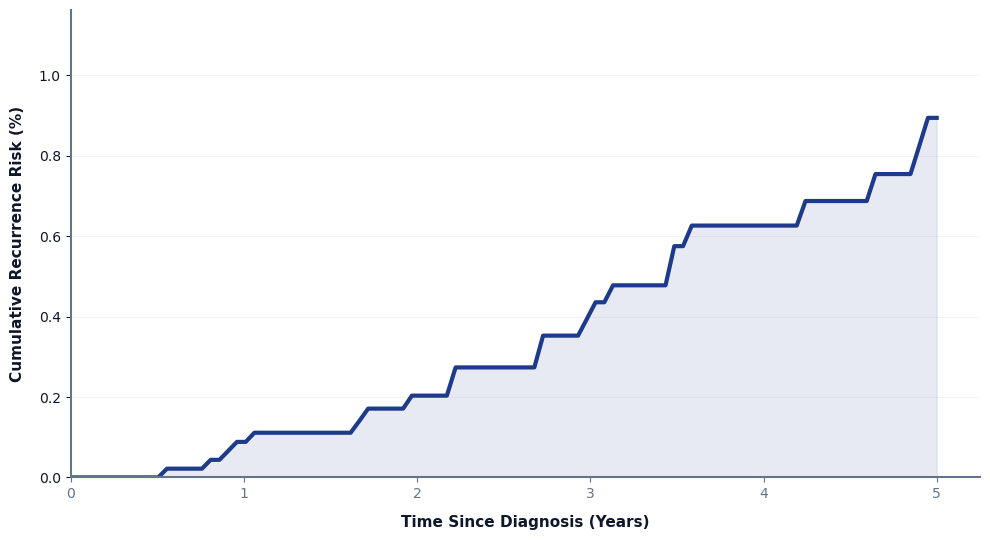

In [ ]:
# 2. Theme Colors (Clinical Precision)
NAVY = '#1E3A8A'
TEAL = '#0D9488'
CRIMSON = '#E11D48'
SLATE = '#0F172A'
MUTED = '#64748B'
GRID_COLOR = '#E2E8F0'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': SLATE,
    'axes.labelcolor': SLATE,
    'xtick.color': MUTED,
    'ytick.color': SLATE,
})

fig, ax = plt.subplots(figsize=(10, 5.5), facecolor='none')
ax.set_facecolor('none')

# 3. Plotting the Risk Curve with UI Fill
ax.plot(time_years, risk_pct, color=NAVY, linewidth=3)
ax.fill_between(time_years, risk_pct, color=NAVY, alpha=0.1) # Gives it the webapp feel

# 4. Highlight the 5-Year Clinical Cutoff 
cutoff_year = 5.0
if max(time_years) >= cutoff_year:
    # Interpolate to find the exact risk percentage at 5 years
    cutoff_risk_pct = np.interp(cutoff_year, time_years, risk_pct)
    
    # Draw vertical dashed line and point
    ax.axvline(cutoff_year, color=CRIMSON, linestyle='--', linewidth=1.5, zorder=2)
    ax.scatter([cutoff_year], [cutoff_risk_pct], color='white', edgecolor=NAVY, s=80, linewidth=2.5, zorder=5)
    
    # Modern floating annotation box
    bbox_props = dict(boxstyle="round,pad=0.6", fc='#F8FAFC', ec=CRIMSON, alpha=0.9, lw=1)
    ax.annotate(
        f"5-Year Risk: {cutoff_risk_pct:.2f}%",
        xy=(cutoff_year, cutoff_risk_pct),
        xytext=(cutoff_year - 1.2, cutoff_risk_pct + (max(risk_pct)*0.15)), # Dynamic positioning
        arrowprops=dict(arrowstyle="-|>", color=CRIMSON, lw=1.5),
        fontsize=10, fontweight='bold', color=CRIMSON,
        bbox=bbox_props
    )

# 5. Clean Formatting
ax.set_xlabel("Time Since Diagnosis (Years)", fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel("Cumulative Recurrence Risk (%)", fontsize=11, fontweight='bold', labelpad=10)

# Remove harsh borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)
ax.spines['left'].set_color(MUTED)
ax.spines['bottom'].set_color(MUTED)

# Horizontal grid only (cleaner for line charts)
ax.grid(axis='y', color=GRID_COLOR, linestyle='-', linewidth=0.5, alpha=0.7)
ax.set_axisbelow(True)

# Dynamic limits to give the chart "breathing room"
ax.set_xlim(0, max(time_years) * 1.05)
ax.set_ylim(0, max(risk_pct) * 1.3) 

plt.tight_layout()

# Export with Transparency
# plt.savefig('patient_risk_hq.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

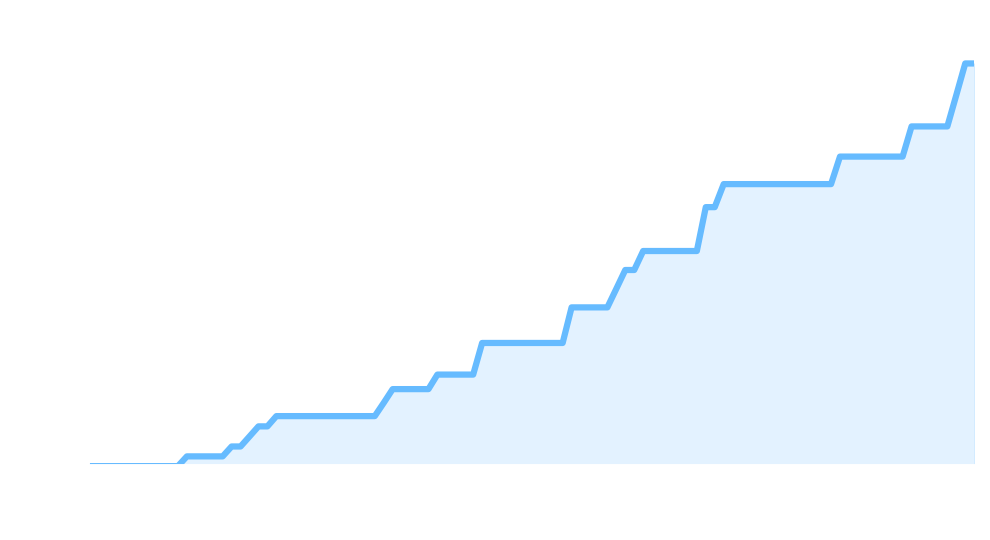

In [ ]:
# ... [Your previous code to get time_grid and risk_prob] ...

# 1. Data Transformation for Doctors
time_years = time_grid / 365.25
risk_pct = risk_prob * 100

patient_id = x_test.index[patient_pos] if hasattr(x_test, "index") else patient_pos

# 2. Theme Colors (Light Scheme for Black Background)
LIGHT_BLUE = '#66BBFF'
BRIGHT_TEAL = '#63E6BE'
CRIMSON = '#E11D48'
WHITE = '#FFFFFF'
LIGHT_BOX_FACE = '#F8FAFC'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': WHITE,
    'axes.labelcolor': WHITE,
    'xtick.color': WHITE,
    'ytick.color': WHITE,
})

fig, ax = plt.subplots(figsize=(10, 5.5), facecolor='none')
ax.set_facecolor('none')

# 3. Plotting the Risk Curve (thicker + bolder look)
ax.plot(time_years, risk_pct, color=LIGHT_BLUE, linewidth=4.5)
ax.fill_between(time_years, risk_pct, color=LIGHT_BLUE, alpha=0.18)

# 4. Highlight the 5-Year Clinical Cutoff
cutoff_year = 5.0
if max(time_years) >= cutoff_year:
    cutoff_risk_pct = np.interp(cutoff_year, time_years, risk_pct)

    ax.axvline(cutoff_year, color=CRIMSON, linestyle='--', linewidth=2.2, zorder=2)
    ax.scatter([cutoff_year], [cutoff_risk_pct], color=WHITE, edgecolor=BRIGHT_TEAL, s=110, linewidth=2.8, zorder=5)

    bbox_props = dict(boxstyle="round,pad=0.6", fc=LIGHT_BOX_FACE, ec=CRIMSON, alpha=0.9, lw=1.5)
    ax.annotate(
        f"5-Year Risk: {cutoff_risk_pct:.2f}%",
        xy=(cutoff_year, cutoff_risk_pct),
        xytext=(cutoff_year - 1.2, cutoff_risk_pct + (max(risk_pct) * 0.15)),
        arrowprops=dict(arrowstyle="-|>", color=CRIMSON, lw=1.8),
        fontsize=12, fontweight='bold', color=CRIMSON,
        bbox=bbox_props
    )

# 5. Clean Formatting (bigger + bold text)
ax.set_xlabel("Years Since Diagnosis", fontsize=14, fontweight='bold', labelpad=12)
ax.set_ylabel("Recurrence Risk", fontsize=14, fontweight='bold', labelpad=12)

# Bolder axis lines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(2.8)
ax.spines['bottom'].set_linewidth(2.8)
ax.spines['left'].set_color(WHITE)
ax.spines['bottom'].set_color(WHITE)

# Bigger/bolder axis tick numbers
ax.tick_params(axis='both', which='major', labelsize=12, width=2.2, length=6, colors=WHITE)
for lbl in ax.get_xticklabels() + ax.get_yticklabels():
    lbl.set_fontweight('bold')

ax.set_axisbelow(True)
ax.margins(x=0, y=0)

x_max = 5.0
y_max = 1.0

x_ticks = np.linspace(0, x_max, 6)
y_ticks = np.linspace(0, y_max, 6)

ax.set_xticks(x_ticks)
ax.set_yticks(y_ticks)
ax.set_xlim(x_ticks[0], x_ticks[-1])
ax.set_ylim(y_ticks[0], y_ticks[-1])

plt.tight_layout()
plt.savefig('patient_risk_hq.png', dpi=300, transparent=True, bbox_inches='tight')
plt.show()


In [18]:
# Animated left-to-right risk curve drawing
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import numpy as np

# Reuse already computed arrays when available
if 'time_years' not in globals() and 'time_grid' in globals():
    time_years = np.asarray(time_grid, dtype=float) / 365.25
if 'risk_pct' not in globals() and 'risk_prob' in globals():
    risk_pct = np.asarray(risk_prob, dtype=float) * 100

if 'time_years' not in globals() or 'risk_pct' not in globals():
    raise ValueError("time_years/risk_pct not found. Run the previous risk-curve cell first.")

time_years_arr = np.asarray(time_years, dtype=float)
risk_pct_arr = np.asarray(risk_pct, dtype=float)

if time_years_arr.shape[0] != risk_pct_arr.shape[0] or time_years_arr.shape[0] < 2:
    raise ValueError("time_years and risk_pct must have same length and at least 2 points.")

# 1. Theme Colors & Settings (Light Scheme for Black Background)
LIGHT_BLUE = '#66BBFF'
WHITE = '#FFFFFF'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': WHITE,
    'axes.labelcolor': WHITE,
    'xtick.color': WHITE,
    'ytick.color': WHITE,
    'animation.embed_limit': 100
})

# 2. Setup Figure (Using black background to match slide)
fig_anim, ax_anim = plt.subplots(figsize=(10, 5.5), facecolor='#262626', dpi=100)
ax_anim.set_facecolor('#262626')

fig_anim.subplots_adjust(bottom=0.2)

# Line only (no shadow/fill)
line_anim, = ax_anim.plot([], [], color=LIGHT_BLUE, linewidth=4.5)

# 3. Clean Formatting (bigger + bold text)
ax_anim.set_xlabel("Years Since Diagnosis", fontsize=14, fontweight='bold', labelpad=12)
ax_anim.set_ylabel("Recurrence Risk (%)", fontsize=14, fontweight='bold', labelpad=12)

# Bolder axis lines
ax_anim.spines['top'].set_visible(False)
ax_anim.spines['right'].set_visible(False)
ax_anim.spines['left'].set_linewidth(2.8)
ax_anim.spines['bottom'].set_linewidth(2.8)
ax_anim.spines['left'].set_color(WHITE)
ax_anim.spines['bottom'].set_color(WHITE)

# Bigger/bolder axis tick numbers
ax_anim.tick_params(axis='both', which='major', labelsize=12, width=2.2, length=6, colors=WHITE)

ax_anim.set_axisbelow(True)
ax_anim.margins(x=0, y=0)

x_max = 5.0
y_max = 2.0

x_ticks = np.linspace(0, x_max, 6)
y_ticks = np.linspace(0, y_max, 6)

ax_anim.set_xticks(x_ticks)
ax_anim.set_yticks(y_ticks)

ax_anim.set_xlim(0, x_max)
ax_anim.set_ylim(0, y_max)

# 4. Animation Logic
def _init():
    line_anim.set_data([], [])
    return (line_anim,)

def _update(frame_idx):
    x = time_years_arr[:frame_idx + 1]
    y = risk_pct_arr[:frame_idx + 1]
    line_anim.set_data(x, y)
    return (line_anim,)

# 5. Duration control (change only this variable)
target_duration_sec = 0.7

# Optional cap for smoother rendering/export on large arrays
max_frames = 180
step = max(1, int(np.ceil(len(time_years_arr) / max_frames)))
frames_to_run = np.arange(0, len(time_years_arr), step, dtype=int)
if frames_to_run[-1] != len(time_years_arr) - 1:
    frames_to_run = np.append(frames_to_run, len(time_years_arr) - 1)

interval_ms = (target_duration_sec * 1000.0) / max(1, len(frames_to_run) - 1)
export_fps = max(1, int(round((len(frames_to_run) - 1) / target_duration_sec)))

anim = FuncAnimation(
    fig_anim,
    _update,
    init_func=_init,
    frames=frames_to_run,
    interval=interval_ms,
    blit=False,
    repeat=False,
)

# Display inline
display(HTML(anim.to_jshtml()))

# Save to MP4
anim.save('patient_risk_animation.mp4', writer='ffmpeg', fps=export_fps, dpi=150)
plt.close(fig_anim)

In [ ]:
# Animated low-threshold curve drawing over STATIC predicted risk
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import numpy as np

# --- 1. DATA PREPARATION ---
if 'time_years' not in globals() and 'time_grid' in globals():
    time_years = np.asarray(time_grid, dtype=float) / 365.25
if 'risk_pct' not in globals() and 'risk_prob' in globals():
    risk_pct = np.asarray(risk_prob, dtype=float) * 100

if 'time_years' not in globals() or 'risk_pct' not in globals():
    raise ValueError("Patient risk data (time_years/risk_pct) not found. Run the patient prediction cell first.")

if 'thresholds_df' in globals() and {'time', 't_low'}.issubset(thresholds_df.columns):
    th_time_raw = np.asarray(thresholds_df['time'], dtype=float)
    t_low_arr = np.asarray(thresholds_df['t_low'], dtype=float)
elif 't_low' in globals():
    t_low_arr = np.asarray(t_low, dtype=float).reshape(-1)
    if 'time_points' in globals() and len(time_points) == len(t_low_arr):
        th_time_raw = np.asarray(time_points, dtype=float)
    else:
        th_time_raw = np.arange(len(t_low_arr), dtype=float)
else:
    raise ValueError("Need either thresholds_df with ['time', 't_low'] or a standalone t_low array.")

valid_mask = np.isfinite(th_time_raw) & np.isfinite(t_low_arr)
th_time_raw = th_time_raw[valid_mask]
t_low_arr = t_low_arr[valid_mask]

if np.nanmax(th_time_raw) > 50:
    th_time_years = th_time_raw / 365.25
else:
    th_time_years = th_time_raw

order = np.argsort(th_time_years)
th_time_years = th_time_years[order]
t_low_arr = t_low_arr[order]

scale = 100.0 if np.nanmax(t_low_arr) <= 1.5 else 1.0
t_low_plot = t_low_arr * scale

# --- 2. THEME SETTINGS ---
DARK_BLUE = '#004C99'
GREEN = '#16A34A'
LIGHT_GREEN = '#DCFCE7'
BLACK = '#000000'
BG = '#F8FAFC'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': BLACK,
    'axes.labelcolor': BLACK,
    'xtick.color': BLACK,
    'ytick.color': BLACK,
    'animation.embed_limit': 100
})

fig_anim, ax_anim = plt.subplots(figsize=(10, 5.5), facecolor=BG)
ax_anim.set_facecolor(BG)

# --- 3. STATIC PATIENT RISK (NO SHADOW) ---
ax_anim.plot(time_years, risk_pct, color=DARK_BLUE, linewidth=3.5, label='Patient Predicted Risk')

# Dynamic threshold line (connected solid line)
line_anim, = ax_anim.plot([], [], color=GREEN, linewidth=4.0, linestyle='-', label='Low Risk Threshold')
fill_poly = [None]

# --- 4. FORMATTING ---
ax_anim.set_xlabel("Years Since Diagnosis", fontsize=14, fontweight='bold', labelpad=12)
ax_anim.set_ylabel("Recurrence Risk (%)", fontsize=14, fontweight='bold', labelpad=12)

ax_anim.spines['top'].set_visible(False)
ax_anim.spines['right'].set_visible(False)
ax_anim.spines['left'].set_linewidth(2.2)
ax_anim.spines['bottom'].set_linewidth(2.2)
ax_anim.spines['left'].set_color(BLACK)
ax_anim.spines['bottom'].set_color(BLACK)

ax_anim.tick_params(axis='both', which='major', labelsize=11, width=1.8, length=5, colors=BLACK)
for lbl in ax_anim.get_xticklabels() + ax_anim.get_yticklabels():
    lbl.set_fontweight('bold')

ax_anim.set_axisbelow(True)

x_max = 5.0
y_max = 3

x_ticks = np.linspace(0, x_max, 6)
y_ticks = np.linspace(0, y_max, 6)

ax_anim.set_xticks(x_ticks)
ax_anim.set_yticks(y_ticks)

ax_anim.set_xlim(0, x_max)
ax_anim.set_ylim(0, y_max)

ax_anim.legend(frameon=False, loc='upper left', fontsize=12)

# --- 5. ANIMATION ---
def _init():
    line_anim.set_data([], [])
    if fill_poly[0] is not None:
        fill_poly[0].remove()
        fill_poly[0] = None
    return (line_anim,)

def _update(frame_idx):
    x = th_time_years[:frame_idx + 1]
    y = t_low_plot[:frame_idx + 1]
    line_anim.set_data(x, y)

    if fill_poly[0] is not None:
        try:
            fill_poly[0].remove()
        except Exception:
            pass
    fill_poly[0] = ax_anim.fill_between(x, y, color=LIGHT_GREEN, alpha=0.3)
    return (line_anim, fill_poly[0])

# Duration control (change only this variable)
target_duration_sec = 1.0

# Optional cap for smoother rendering/export on large arrays
max_frames = 180
step = max(1, int(np.ceil(len(th_time_years) / max_frames)))
frames_to_run = np.arange(0, len(th_time_years), step, dtype=int)
if frames_to_run[-1] != len(th_time_years) - 1:
    frames_to_run = np.append(frames_to_run, len(th_time_years) - 1)

interval_ms = (target_duration_sec * 1000.0) / max(1, len(frames_to_run) - 1)
export_fps = max(1, int(round((len(frames_to_run) - 1) / target_duration_sec)))

anim = FuncAnimation(
    fig_anim,
    _update,
    init_func=_init,
    frames=frames_to_run,
    interval=interval_ms,
    blit=False,
    repeat=False,
)

display(HTML(anim.to_jshtml()))
anim.save('t_low.mp4', writer='ffmpeg', fps=export_fps)
plt.close(fig_anim)

In [33]:
# Animated medium-threshold curve drawing over STATIC patient + low risk
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import numpy as np

# --- 1. DATA PREPARATION ---
if 'time_years' not in globals() and 'time_grid' in globals():
    time_years = np.asarray(time_grid, dtype=float) / 365.25
if 'risk_pct' not in globals() and 'risk_prob' in globals():
    risk_pct = np.asarray(risk_prob, dtype=float) * 100

if 'time_years' not in globals() or 'risk_pct' not in globals():
    raise ValueError("Patient risk data (time_years/risk_pct) not found. Run the patient prediction cell first.")

if 'thresholds_df' in globals() and 'time' in thresholds_df.columns:
    th_time_raw = np.asarray(thresholds_df['time'], dtype=float)

    low_col = next((c for c in ['t_low', 'low', 'low_risk'] if c in thresholds_df.columns), None)
    med_col = next((c for c in ['t_intermediate', 't_medium', 't_med', 't_mid', 'intermediate', 'medium', 'med_risk'] if c in thresholds_df.columns), None)

    if low_col is None:
        raise ValueError("Could not find low-risk threshold column (e.g., t_low) in thresholds_df.")
    if med_col is None:
        raise ValueError("Could not find intermediate-risk threshold column (e.g., t_intermediate) in thresholds_df.")

    t_low_arr = np.asarray(thresholds_df[low_col], dtype=float)
    t_med_arr = np.asarray(thresholds_df[med_col], dtype=float)
else:
    if 't_low' not in globals():
        raise ValueError("Need low-risk data: provide thresholds_df['t_low'] or a standalone t_low array.")

    med_source = None
    for candidate in ['t_intermediate', 't_medium', 't_med', 't_mid']:
        if candidate in globals():
            med_source = candidate
            break

    if med_source is None:
        raise ValueError("Need intermediate-risk data: provide thresholds_df or one of t_intermediate/t_medium/t_med/t_mid.")

    t_low_arr = np.asarray(t_low, dtype=float).reshape(-1)
    t_med_arr = np.asarray(globals()[med_source], dtype=float).reshape(-1)

    if 'time_points' in globals() and len(time_points) == len(t_low_arr):
        th_time_raw = np.asarray(time_points, dtype=float)
    else:
        th_time_raw = np.arange(len(t_low_arr), dtype=float)

# Keep only rows where all three arrays are finite
valid_mask = np.isfinite(th_time_raw) & np.isfinite(t_low_arr) & np.isfinite(t_med_arr)
th_time_raw = th_time_raw[valid_mask]
t_low_arr = t_low_arr[valid_mask]
t_med_arr = t_med_arr[valid_mask]

if np.nanmax(th_time_raw) > 50:
    th_time_years = th_time_raw / 365.25
else:
    th_time_years = th_time_raw

order = np.argsort(th_time_years)
th_time_years = th_time_years[order]
t_low_arr = t_low_arr[order]
t_med_arr = t_med_arr[order]

# If thresholds are probabilities, convert to percentage to match risk_pct
threshold_max = max(float(np.nanmax(t_low_arr)), float(np.nanmax(t_med_arr)))
scale = 100.0 if threshold_max <= 1.5 else 1.0
t_low_plot = t_low_arr * scale
t_med_plot = t_med_arr * scale

# --- 2. THEME SETTINGS ---
DARK_BLUE = '#004C99'
GREEN = '#16A34A'
ORANGE = '#F59E0B'
BLACK = '#000000'
BG = '#F8FAFC'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': BLACK,
    'axes.labelcolor': BLACK,
    'xtick.color': BLACK,
    'ytick.color': BLACK,
    'animation.embed_limit': 100
})

fig_anim, ax_anim = plt.subplots(figsize=(10, 5.5), facecolor=BG)
ax_anim.set_facecolor(BG)

# --- 3. STATIC CURVES: PATIENT + LOW ---
ax_anim.plot(time_years, risk_pct, color=DARK_BLUE, linewidth=3.5, label='Patient Predicted Risk')
ax_anim.plot(th_time_years, t_low_plot, color=GREEN, linewidth=3.0, linestyle='-', label='Low Risk Threshold')

# Dynamic intermediate-threshold line
line_anim, = ax_anim.plot([], [], color=ORANGE, linewidth=4.0, linestyle='-', label='Intermediate Risk Threshold')

# --- 4. FORMATTING ---
ax_anim.set_xlabel("Years Since Diagnosis", fontsize=14, fontweight='bold', labelpad=12)
ax_anim.set_ylabel("Recurrence Risk (%)", fontsize=14, fontweight='bold', labelpad=12)

ax_anim.spines['top'].set_visible(False)
ax_anim.spines['right'].set_visible(False)
ax_anim.spines['left'].set_linewidth(2.2)
ax_anim.spines['bottom'].set_linewidth(2.2)
ax_anim.spines['left'].set_color(BLACK)
ax_anim.spines['bottom'].set_color(BLACK)

ax_anim.tick_params(axis='both', which='major', labelsize=11, width=1.8, length=5, colors=BLACK)
for lbl in ax_anim.get_xticklabels() + ax_anim.get_yticklabels():
    lbl.set_fontweight('bold')

ax_anim.set_axisbelow(True)

x_max = max(float(np.nanmax(time_years)), float(np.nanmax(th_time_years)))
y_max = max(
    float(np.nanmax(risk_pct)),
    float(np.nanmax(t_low_plot)),
    float(np.nanmax(t_med_plot))
) * 1.15

x_ticks = np.linspace(0, x_max, 6)
y_ticks = np.linspace(0, y_max, 6)

ax_anim.set_xticks(x_ticks)
ax_anim.set_yticks(y_ticks)

ax_anim.set_xlim(0, x_max)
ax_anim.set_ylim(0, y_max)

ax_anim.legend(frameon=False, loc='upper left', fontsize=12)

# --- 5. ANIMATION (INTERMEDIATE RISK ONLY) ---
def _init():
    line_anim.set_data([], [])
    return (line_anim,)

def _update(frame_idx):
    x = th_time_years[:frame_idx + 1]
    y = t_med_plot[:frame_idx + 1]
    line_anim.set_data(x, y)
    return (line_anim,)

# Duration control (change only this variable)
target_duration_sec = 1.0

# Optional cap for smoother rendering/export on large arrays
max_frames = 180
step = max(1, int(np.ceil(len(th_time_years) / max_frames)))
frames_to_run = np.arange(0, len(th_time_years), step, dtype=int)
if frames_to_run[-1] != len(th_time_years) - 1:
    frames_to_run = np.append(frames_to_run, len(th_time_years) - 1)

interval_ms = (target_duration_sec * 1000.0) / max(1, len(frames_to_run) - 1)
export_fps = max(1, int(round((len(frames_to_run) - 1) / target_duration_sec)))

anim = FuncAnimation(
    fig_anim,
    _update,
    init_func=_init,
    frames=frames_to_run,
    interval=interval_ms,
    blit=False,
    repeat=False,
)

display(HTML(anim.to_jshtml()))
anim.save('t_intermediate.mp4', writer='ffmpeg', fps=export_fps)
plt.close(fig_anim)

In [8]:
# Animated high-threshold curve drawing over STATIC patient + low + intermediate risk
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import numpy as np

# --- 1. DATA PREPARATION ---
if 'time_years' not in globals() and 'time_grid' in globals():
    time_years = np.asarray(time_grid, dtype=float) / 365.25
if 'risk_pct' not in globals() and 'risk_prob' in globals():
    risk_pct = np.asarray(risk_prob, dtype=float) * 100

if 'time_years' not in globals() or 'risk_pct' not in globals():
    raise ValueError("Patient risk data (time_years/risk_pct) not found. Run the patient prediction cell first.")

# We already have thresholds loaded (thresholds_df + t_low/t_intermediate/t_high)
if 'thresholds_df' in globals() and {'time', 't_low', 't_intermediate', 't_high'}.issubset(thresholds_df.columns):
    th_time_raw = np.asarray(thresholds_df['time'], dtype=float)
    t_low_arr = np.asarray(thresholds_df['t_low'], dtype=float)
    t_inter_arr = np.asarray(thresholds_df['t_intermediate'], dtype=float)
    t_high_arr = np.asarray(thresholds_df['t_high'], dtype=float)
else:
    # Fallback to arrays if thresholds_df is unavailable
    needed = ['t_low', 't_intermediate', 't_high']
    missing = [k for k in needed if k not in globals()]
    if missing:
        raise ValueError(f"Missing thresholds in globals: {missing}. Run the thresholds loading cell first.")

    t_low_arr = np.asarray(t_low, dtype=float).reshape(-1)
    t_inter_arr = np.asarray(t_intermediate, dtype=float).reshape(-1)
    t_high_arr = np.asarray(t_high, dtype=float).reshape(-1)

    if 'time_points' in globals() and len(time_points) == len(t_low_arr):
        th_time_raw = np.asarray(time_points, dtype=float)
    else:
        th_time_raw = np.arange(len(t_low_arr), dtype=float)

# Keep only rows where all arrays are finite
valid_mask = (
    np.isfinite(th_time_raw)
    & np.isfinite(t_low_arr)
    & np.isfinite(t_inter_arr)
    & np.isfinite(t_high_arr)
)
th_time_raw = th_time_raw[valid_mask]
t_low_arr = t_low_arr[valid_mask]
t_inter_arr = t_inter_arr[valid_mask]
t_high_arr = t_high_arr[valid_mask]

if np.nanmax(th_time_raw) > 50:
    th_time_years = th_time_raw / 365.25
else:
    th_time_years = th_time_raw

order = np.argsort(th_time_years)
th_time_years = th_time_years[order]
t_low_arr = t_low_arr[order]
t_inter_arr = t_inter_arr[order]
t_high_arr = t_high_arr[order]

# If thresholds are probabilities, convert to percentage to match risk_pct
threshold_max = max(
    float(np.nanmax(t_low_arr)),
    float(np.nanmax(t_inter_arr)),
    float(np.nanmax(t_high_arr))
)
scale = 100.0 if threshold_max <= 1.5 else 1.0
t_low_plot = t_low_arr * scale
t_inter_plot = t_inter_arr * scale
t_high_plot = t_high_arr * scale

# --- 2. THEME SETTINGS ---
DARK_BLUE = '#004C99'
GREEN = '#16A34A'
ORANGE = '#F59E0B'
CRIMSON = '#E11D48'
BLACK = '#000000'
BG = '#F8FAFC'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': BLACK,
    'axes.labelcolor': BLACK,
    'xtick.color': BLACK,
    'ytick.color': BLACK,
    'animation.embed_limit': 100
})

fig_anim, ax_anim = plt.subplots(figsize=(10, 5.5), facecolor=BG)
ax_anim.set_facecolor(BG)

# --- 3. STATIC CURVES: PATIENT + LOW + INTERMEDIATE ---
ax_anim.plot(time_years, risk_pct, color=DARK_BLUE, linewidth=3.5, label='Patient Predicted Risk')
ax_anim.plot(th_time_years, t_low_plot, color=GREEN, linewidth=3.0, linestyle='-', label='Low Risk Threshold')
ax_anim.plot(th_time_years, t_inter_plot, color=ORANGE, linewidth=3.0, linestyle='-', label='Intermediate Risk Threshold')

# Dynamic high-threshold line
line_anim, = ax_anim.plot([], [], color=CRIMSON, linewidth=4.0, linestyle='-', label='High Risk Threshold')

# --- 4. FORMATTING ---
ax_anim.set_xlabel("Years Since Diagnosis", fontsize=14, fontweight='bold', labelpad=12)
ax_anim.set_ylabel("Recurrence Risk (%)", fontsize=14, fontweight='bold', labelpad=12)

ax_anim.spines['top'].set_visible(False)
ax_anim.spines['right'].set_visible(False)
ax_anim.spines['left'].set_linewidth(2.2)
ax_anim.spines['bottom'].set_linewidth(2.2)
ax_anim.spines['left'].set_color(BLACK)
ax_anim.spines['bottom'].set_color(BLACK)

ax_anim.tick_params(axis='both', which='major', labelsize=11, width=1.8, length=5, colors=BLACK)
for lbl in ax_anim.get_xticklabels() + ax_anim.get_yticklabels():
    lbl.set_fontweight('bold')

ax_anim.set_axisbelow(True)

x_max = max(float(np.nanmax(time_years)), float(np.nanmax(th_time_years)))
y_max = max(
    float(np.nanmax(risk_pct)),
    float(np.nanmax(t_low_plot)),
    float(np.nanmax(t_inter_plot)),
    float(np.nanmax(t_high_plot))
) * 1.15

x_ticks = np.linspace(0, x_max, 6)
y_ticks = np.linspace(0, y_max, 6)

ax_anim.set_xticks(x_ticks)
ax_anim.set_yticks(y_ticks)

ax_anim.set_xlim(0, x_max)
ax_anim.set_ylim(0, y_max)

ax_anim.legend(frameon=False, loc='upper left', fontsize=12)

# --- 5. ANIMATION (HIGH RISK ONLY) ---
def _init():
    line_anim.set_data([], [])
    return (line_anim,)

def _update(frame_idx):
    x = th_time_years[:frame_idx + 1]
    y = t_high_plot[:frame_idx + 1]
    line_anim.set_data(x, y)
    return (line_anim,)

# Duration control (change only this variable)
target_duration_sec = 1.0

# Optional cap for smoother rendering/export on large arrays
max_frames = 180
step = max(1, int(np.ceil(len(th_time_years) / max_frames)))
frames_to_run = np.arange(0, len(th_time_years), step, dtype=int)
if frames_to_run[-1] != len(th_time_years) - 1:
    frames_to_run = np.append(frames_to_run, len(th_time_years) - 1)

interval_ms = (target_duration_sec * 1000.0) / max(1, len(frames_to_run) - 1)
export_fps = max(1, int(round((len(frames_to_run) - 1) / target_duration_sec)))

anim = FuncAnimation(
    fig_anim,
    _update,
    init_func=_init,
    frames=frames_to_run,
    interval=interval_ms,
    blit=False,
    repeat=False,
)

display(HTML(anim.to_jshtml()))
anim.save('t_high.mp4', writer='ffmpeg', fps=export_fps)
plt.close(fig_anim)

In [26]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import numpy as np

if 'time_years' not in globals() and 'time_grid' in globals():
    time_years = np.asarray(time_grid, dtype=float) / 365.25
if 'risk_pct' not in globals() and 'risk_prob' in globals():
    risk_pct = np.asarray(risk_prob, dtype=float) * 100

if 'time_years' not in globals() or 'risk_pct' not in globals():
    raise ValueError("Patient risk data (time_years/risk_pct) not found. Run the patient prediction cell first.")

if 'thresholds_df' in globals() and {'time', 't_low', 't_intermediate', 't_high'}.issubset(thresholds_df.columns):
    th_time_raw = np.asarray(thresholds_df['time'], dtype=float)
    t_low_arr = np.asarray(thresholds_df['t_low'], dtype=float)
    t_inter_arr = np.asarray(thresholds_df['t_intermediate'], dtype=float)
    t_high_arr = np.asarray(thresholds_df['t_high'], dtype=float)
else:
    needed = ['t_low', 't_intermediate', 't_high']
    missing = [k for k in needed if k not in globals()]
    if missing:
        raise ValueError(f"Missing thresholds in globals: {missing}. Run the thresholds loading cell first.")

    t_low_arr = np.asarray(t_low, dtype=float).reshape(-1)
    t_inter_arr = np.asarray(t_intermediate, dtype=float).reshape(-1)
    t_high_arr = np.asarray(t_high, dtype=float).reshape(-1)

    if 'time_points' in globals() and len(time_points) == len(t_low_arr):
        th_time_raw = np.asarray(time_points, dtype=float)
    else:
        th_time_raw = np.arange(len(t_low_arr), dtype=float)

valid_mask = np.isfinite(th_time_raw) & np.isfinite(t_low_arr) & np.isfinite(t_inter_arr) & np.isfinite(t_high_arr)
th_time_raw = th_time_raw[valid_mask]
t_low_arr = t_low_arr[valid_mask]
t_inter_arr = t_inter_arr[valid_mask]
t_high_arr = t_high_arr[valid_mask]

th_time_years = th_time_raw / 365.25 if np.nanmax(th_time_raw) > 50 else th_time_raw
order = np.argsort(th_time_years)
th_time_years = th_time_years[order]
t_low_arr = t_low_arr[order]
t_inter_arr = t_inter_arr[order]
t_high_arr = t_high_arr[order]

threshold_max = max(float(np.nanmax(t_low_arr)), float(np.nanmax(t_inter_arr)), float(np.nanmax(t_high_arr)))
scale = 100.0 if threshold_max <= 1.5 else 1.0
t_low_plot = t_low_arr * scale
t_inter_plot = t_inter_arr * scale
t_high_plot = t_high_arr * scale

DARK_BLUE = '#004C99'
GREEN = '#16A34A'
ORANGE = '#F59E0B'
CRIMSON = '#E11D48'
# BLACK = '#000000'
BLACK = '#FFFFFF'
# BG = '#F8FAFC'
BG = '#0D948873'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': BLACK,
    'axes.labelcolor': BLACK,
    'xtick.color': BLACK,
    'ytick.color': BLACK,
    'animation.embed_limit': 100
})

fig_anim, ax_anim = plt.subplots(figsize=(10, 5.5), facecolor=BG)
ax_anim.set_facecolor('none')

fig_anim.subplots_adjust(bottom=0.2)

ax_anim.plot(time_years, risk_pct, color=DARK_BLUE, linewidth=3.5, label='Patient Predicted Risk')

line_low, = ax_anim.plot([], [], color=GREEN, linewidth=3.5, linestyle='-', label='Low Risk Threshold')
line_inter, = ax_anim.plot([], [], color=ORANGE, linewidth=3.5, linestyle='-', label='Intermediate Risk Threshold')
line_high, = ax_anim.plot([], [], color=CRIMSON, linewidth=3.5, linestyle='-', label='High Risk Threshold')

ax_anim.set_xlabel('Years Since Diagnosis', fontsize=14, fontweight='bold', labelpad=12)
ax_anim.set_ylabel('Recurrence Risk (%)', fontsize=14, fontweight='bold', labelpad=12)

ax_anim.spines['top'].set_visible(False)
ax_anim.spines['right'].set_visible(False)
ax_anim.spines['left'].set_linewidth(2.2)
ax_anim.spines['bottom'].set_linewidth(2.2)
ax_anim.spines['left'].set_color(BLACK)
ax_anim.spines['bottom'].set_color(BLACK)

ax_anim.tick_params(axis='both', which='major', labelsize=11, width=1.8, length=5, colors=BLACK)
for lbl in ax_anim.get_xticklabels() + ax_anim.get_yticklabels():
    lbl.set_fontweight('bold')

x_max = 5.0
y_max = max(float(np.nanmax(risk_pct)), float(np.nanmax(t_low_plot)), float(np.nanmax(t_inter_plot)), float(np.nanmax(t_high_plot))) * 1.15
ax_anim.set_xlim(0, x_max)
ax_anim.set_ylim(0, y_max)

# ax_anim.legend(frameon=False, loc='upper left', fontsize=12)

def _init():
    line_low.set_data([], [])
    line_inter.set_data([], [])
    line_high.set_data([], [])
    return (line_low, line_inter, line_high)

def _update(frame_idx):
    x = th_time_years[:frame_idx + 1]
    line_low.set_data(x, t_low_plot[:frame_idx + 1])
    line_inter.set_data(x, t_inter_plot[:frame_idx + 1])
    line_high.set_data(x, t_high_plot[:frame_idx + 1])
    return (line_low, line_inter, line_high)

target_duration_sec = 1.0
max_frames = 180
step = max(1, int(np.ceil(len(th_time_years) / max_frames)))
frames_to_run = np.arange(0, len(th_time_years), step, dtype=int)
if frames_to_run[-1] != len(th_time_years) - 1:
    frames_to_run = np.append(frames_to_run, len(th_time_years) - 1)

interval_ms = (target_duration_sec * 1000.0) / max(1, len(frames_to_run) - 1)
export_fps = max(1, int(round((len(frames_to_run) - 1) / target_duration_sec)))

anim = FuncAnimation(
    fig_anim,
    _update,
    init_func=_init,
    frames=frames_to_run,
    interval=interval_ms,
    blit=False,
    repeat=False,
)

display(HTML(anim.to_jshtml()))
anim.save('all_thresholds_growing.mp4', writer='ffmpeg', fps=export_fps)
plt.close(fig_anim)

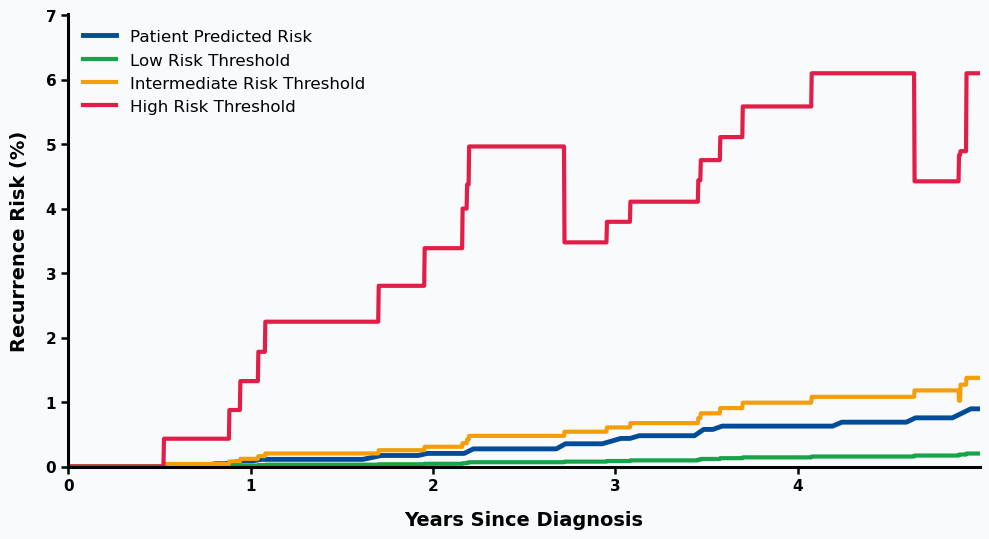

In [ ]:
# Static figure: patient risk + all thresholds (no animation)
import matplotlib.pyplot as plt
import numpy as np

if 'time_years' not in globals() and 'time_grid' in globals():
    time_years = np.asarray(time_grid, dtype=float) / 365.25
if 'risk_pct' not in globals() and 'risk_prob' in globals():
    risk_pct = np.asarray(risk_prob, dtype=float) * 100

if 'time_years' not in globals() or 'risk_pct' not in globals():
    raise ValueError("Patient risk data (time_years/risk_pct) not found. Run the patient prediction cell first.")

if 'thresholds_df' in globals() and {'time', 't_low', 't_intermediate', 't_high'}.issubset(thresholds_df.columns):
    th_time_raw = np.asarray(thresholds_df['time'], dtype=float)
    t_low_arr = np.asarray(thresholds_df['t_low'], dtype=float)
    t_inter_arr = np.asarray(thresholds_df['t_intermediate'], dtype=float)
    t_high_arr = np.asarray(thresholds_df['t_high'], dtype=float)
else:
    needed = ['t_low', 't_intermediate', 't_high']
    missing = [k for k in needed if k not in globals()]
    if missing:
        raise ValueError(f"Missing thresholds in globals: {missing}. Run the thresholds loading cell first.")

    t_low_arr = np.asarray(t_low, dtype=float).reshape(-1)
    t_inter_arr = np.asarray(t_intermediate, dtype=float).reshape(-1)
    t_high_arr = np.asarray(t_high, dtype=float).reshape(-1)

    if 'time_points' in globals() and len(time_points) == len(t_low_arr):
        th_time_raw = np.asarray(time_points, dtype=float)
    else:
        th_time_raw = np.arange(len(t_low_arr), dtype=float)

valid_mask = np.isfinite(th_time_raw) & np.isfinite(t_low_arr) & np.isfinite(t_inter_arr) & np.isfinite(t_high_arr)
th_time_raw = th_time_raw[valid_mask]
t_low_arr = t_low_arr[valid_mask]
t_inter_arr = t_inter_arr[valid_mask]
t_high_arr = t_high_arr[valid_mask]

th_time_years = th_time_raw / 365.25 if np.nanmax(th_time_raw) > 50 else th_time_raw
order = np.argsort(th_time_years)
th_time_years = th_time_years[order]
t_low_arr = t_low_arr[order]
t_inter_arr = t_inter_arr[order]
t_high_arr = t_high_arr[order]

threshold_max = max(float(np.nanmax(t_low_arr)), float(np.nanmax(t_inter_arr)), float(np.nanmax(t_high_arr)))
scale = 100.0 if threshold_max <= 1.5 else 1.0
t_low_plot = t_low_arr * scale
t_inter_plot = t_inter_arr * scale
t_high_plot = t_high_arr * scale

DARK_BLUE = '#004C99'
GREEN = '#16A34A'
ORANGE = '#F59E0B'
CRIMSON = '#E11D48'
BLACK = '#000000'
BG = '#F8FAFC'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': BLACK,
    'axes.labelcolor': BLACK,
    'xtick.color': BLACK,
    'ytick.color': BLACK,
})

fig_static, ax_static = plt.subplots(figsize=(10, 5.5), facecolor=BG)
ax_static.set_facecolor(BG)

ax_static.plot(time_years, risk_pct, color=DARK_BLUE, linewidth=3.5, label='Patient Predicted Risk')
ax_static.plot(th_time_years, t_low_plot, color=GREEN, linewidth=3.0, linestyle='-', label='Low Risk Threshold')
ax_static.plot(th_time_years, t_inter_plot, color=ORANGE, linewidth=3.0, linestyle='-', label='Intermediate Risk Threshold')
ax_static.plot(th_time_years, t_high_plot, color=CRIMSON, linewidth=3.0, linestyle='-', label='High Risk Threshold')

ax_static.set_xlabel('Years Since Diagnosis', fontsize=14, fontweight='bold', labelpad=12)
ax_static.set_ylabel('Recurrence Risk (%)', fontsize=14, fontweight='bold', labelpad=12)

ax_static.spines['top'].set_visible(False)
ax_static.spines['right'].set_visible(False)
ax_static.spines['left'].set_linewidth(2.2)
ax_static.spines['bottom'].set_linewidth(2.2)
ax_static.spines['left'].set_color(BLACK)
ax_static.spines['bottom'].set_color(BLACK)

ax_static.tick_params(axis='both', which='major', labelsize=11, width=1.8, length=5, colors=BLACK)
for lbl in ax_static.get_xticklabels() + ax_static.get_yticklabels():
    lbl.set_fontweight('bold')

x_max = 5.0
y_max = max(float(np.nanmax(risk_pct)), float(np.nanmax(t_low_plot)), float(np.nanmax(t_inter_plot)), float(np.nanmax(t_high_plot))) * 1.15
ax_static.set_xlim(0, x_max)
ax_static.set_ylim(0, y_max)

ax_static.legend(frameon=False, loc='upper left', fontsize=12)
plt.tight_layout()
plt.savefig('thresholds_static.png', dpi=300, transparent=False, bbox_inches='tight')
plt.show()

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import numpy as np

# ---------------------------
# 1) Thresholds only: old from thresholds_df, new from thresholds_df_2
# ---------------------------
if 'thresholds_df' not in globals() or 't_low' not in thresholds_df.columns:
    raise ValueError("thresholds_df with column 't_low' is required.")
if 'thresholds_df_2' not in globals() or 't_low' not in thresholds_df_2.columns:
    raise ValueError("thresholds_df_2 with column 't_low' is required.")

old_raw = np.asarray(thresholds_df['t_low'], dtype=float)
new_raw = np.asarray(thresholds_df_2['t_low'], dtype=float)

if 'time' in thresholds_df.columns:
    old_time_raw = np.asarray(thresholds_df['time'], dtype=float)
elif 'time_points' in globals() and len(time_points) == len(old_raw):
    old_time_raw = np.asarray(time_points, dtype=float)
else:
    old_time_raw = np.arange(len(old_raw), dtype=float)

if 'time' in thresholds_df_2.columns:
    new_time_raw = np.asarray(thresholds_df_2['time'], dtype=float)
elif 'time_points' in globals() and len(time_points) == len(new_raw):
    new_time_raw = np.asarray(time_points, dtype=float)
else:
    new_time_raw = np.arange(len(new_raw), dtype=float)

m_old = np.isfinite(old_time_raw) & np.isfinite(old_raw)
m_new = np.isfinite(new_time_raw) & np.isfinite(new_raw)
old_time_raw, old_raw = old_time_raw[m_old], old_raw[m_old]
new_time_raw, new_raw = new_time_raw[m_new], new_raw[m_new]

old_time = old_time_raw / 365.25 if np.nanmax(old_time_raw) > 50 else old_time_raw
new_time = new_time_raw / 365.25 if np.nanmax(new_time_raw) > 50 else new_time_raw

ord_old = np.argsort(old_time)
ord_new = np.argsort(new_time)
old_time, old_raw = old_time[ord_old], old_raw[ord_old]
new_time, new_raw = new_time[ord_new], new_raw[ord_new]

# Put new threshold on old time axis so both evolve in lockstep
new_on_old = np.interp(old_time, new_time, new_raw)

thr_max = max(float(np.nanmax(old_raw)), float(np.nanmax(new_on_old)))
scale = 100.0 if thr_max <= 1.5 else 1.0
old_tlow = old_raw * scale
new_tlow = new_on_old * scale

if old_time.size < 2:
    raise ValueError("Not enough threshold points to animate.")

# ---------------------------
# 2) Plot (NO patient predicted risk)
# ---------------------------
GREY = "#7EE6D9"
BLACK = '#000000'
BG = '#F8FAFC'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': BLACK,
    'axes.labelcolor': BLACK,
    'xtick.color': BLACK,
    'ytick.color': BLACK,
    'animation.embed_limit': 100
})

fig_anim, ax_anim = plt.subplots(figsize=(10, 5.5), facecolor=BG)
ax_anim.set_facecolor(BG)

# Old starts full, new starts empty
line_old, = ax_anim.plot([], [], color=GREY, linewidth=3.8, label='raw threshold')
line_new, = ax_anim.plot([], [], color=GREY, linewidth=3.8, label='restricted cubic spline transformation')

ax_anim.set_xlabel('Years Since Diagnosis', fontsize=14, fontweight='bold', labelpad=12)
ax_anim.set_ylabel('Recurrence Risk (%)', fontsize=14, fontweight='bold', labelpad=12)

ax_anim.spines['top'].set_visible(False)
ax_anim.spines['right'].set_visible(False)
ax_anim.spines['left'].set_linewidth(2.2)
ax_anim.spines['bottom'].set_linewidth(2.2)
ax_anim.spines['left'].set_color(BLACK)
ax_anim.spines['bottom'].set_color(BLACK)

ax_anim.tick_params(axis='both', which='major', labelsize=11, width=1.8, length=5, colors=BLACK)
for lbl in ax_anim.get_xticklabels() + ax_anim.get_yticklabels():
    lbl.set_fontweight('bold')

x_max = 5.0
y_max = max(float(np.nanmax(old_tlow)), float(np.nanmax(new_tlow))) * 1.15
ax_anim.set_xlim(0, x_max)
ax_anim.set_ylim(0, y_max)

# ---------------------------
# 3) Animation:
# old disappears LEFT->RIGHT while new appears LEFT->RIGHT
# ---------------------------
target_duration_sec = 1.0
max_frames = 220
step = max(1, int(np.ceil(len(old_time) / max_frames)))
frames_to_run = np.arange(0, len(old_time), step, dtype=int)
if frames_to_run[-1] != len(old_time) - 1:
    frames_to_run = np.append(frames_to_run, len(old_time) - 1)

def _init():
    line_old.set_data(old_time, old_tlow)  # fully visible at start
    line_new.set_data([], [])              # invisible at start
    return (line_old, line_new)

def _update(k):
    idx = frames_to_run[k]

    # New appears from left to right
    line_new.set_data(old_time[:idx + 1], new_tlow[:idx + 1])

    # Old disappears from left to right
    line_old.set_data(old_time[idx + 1:], old_tlow[idx + 1:])

    return (line_old, line_new)

interval_ms = (target_duration_sec * 1000.0) / max(1, len(frames_to_run) - 1)
export_fps = max(1, int(round((len(frames_to_run) - 1) / target_duration_sec)))

anim = FuncAnimation(
    fig_anim,
    _update,
    init_func=_init,
    frames=len(frames_to_run),
    interval=interval_ms,
    blit=False,
    repeat=False,
)

display(HTML(anim.to_jshtml()))
anim.save('t_low_swap_left_to_right_no_risk.mp4', writer='ffmpeg', fps=export_fps)
plt.close(fig_anim)

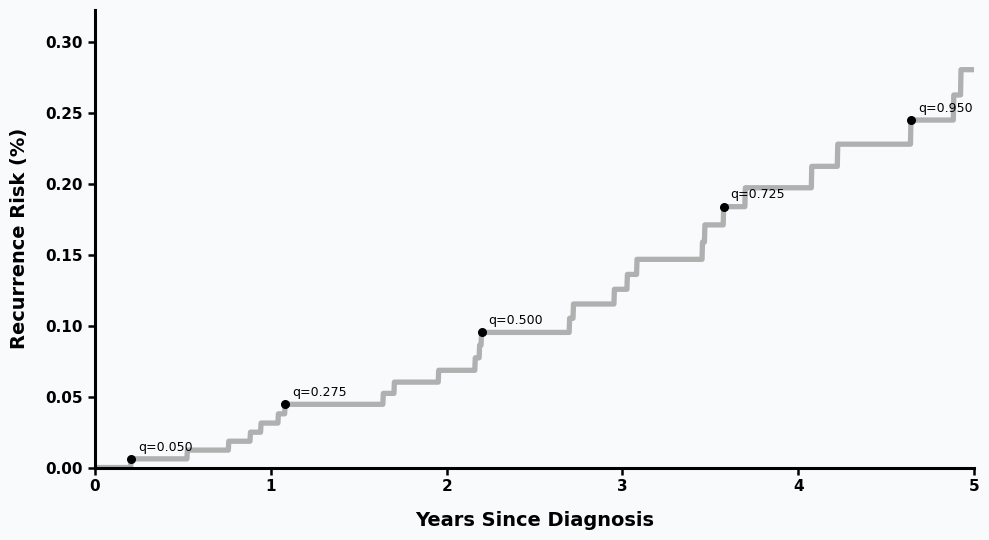

In [36]:
import matplotlib.pyplot as plt
import numpy as np

# =========================
# Options
# =========================
SHOW_QUANTILES = True
QUANTILE_LEVELS = [0.05, 0.275, 0.5, 0.725, 0.95]

# =========================
# 1) Get t_low + time
# =========================
if "thresholds_df" in globals() and "t_low" in thresholds_df.columns:
    t_low_raw = np.asarray(thresholds_df["t_low"], dtype=float)

    if "time" in thresholds_df.columns:
        time_raw = np.asarray(thresholds_df["time"], dtype=float)
    elif "time_points" in globals() and len(time_points) == len(t_low_raw):
        time_raw = np.asarray(time_points, dtype=float)
    else:
        time_raw = np.arange(len(t_low_raw), dtype=float)

elif "t_low" in globals():
    t_low_raw = np.asarray(t_low, dtype=float).reshape(-1)

    if "time_points" in globals() and len(time_points) == len(t_low_raw):
        time_raw = np.asarray(time_points, dtype=float)
    else:
        time_raw = np.arange(len(t_low_raw), dtype=float)

else:
    raise ValueError("Need thresholds_df['t_low'] or standalone t_low.")

# Keep finite values only
mask = np.isfinite(time_raw) & np.isfinite(t_low_raw)
time_raw = time_raw[mask]
t_low_raw = t_low_raw[mask]

if time_raw.size < 2:
    raise ValueError("Not enough valid points to plot t_low.")

# Convert time to years if likely in days
time_years = time_raw / 365.25 if np.nanmax(time_raw) > 50 else time_raw

# Sort by time
order = np.argsort(time_years)
time_years = time_years[order]
t_low_raw = t_low_raw[order]

# Convert thresholds to percent if stored as probabilities
scale = 100.0 if float(np.nanmax(t_low_raw)) <= 1.5 else 1.0
t_low_plot = t_low_raw * scale

# =========================
# 2) Plot
# =========================
GREY = "#AEB1AF"
BLACK = "#000000"
BG = "#F8FAFC"

plt.rcParams.update({
    "font.family": "sans-serif",
    "text.color": BLACK,
    "axes.labelcolor": BLACK,
    "xtick.color": BLACK,
    "ytick.color": BLACK
})

fig, ax = plt.subplots(figsize=(10, 5.5), facecolor=BG)
ax.set_facecolor(BG)

ax.plot(time_years, t_low_plot, color=GREY, linewidth=3.8, label="t_low")

# Optional quantile markers on the curve
if SHOW_QUANTILES:
    q_vals = np.quantile(t_low_plot, QUANTILE_LEVELS)
    for i, (q, qv) in enumerate(zip(QUANTILE_LEVELS, q_vals)):
        idx = int(np.argmin(np.abs(t_low_plot - qv)))
        xq, yq = float(time_years[idx]), float(t_low_plot[idx])

        ax.scatter([xq], [yq], color=BLACK, s=30, zorder=5, label="Quantiles" if i == 0 else None)
        ax.annotate(
            f"q={q:.3f}",
            (xq, yq),
            xytext=(5, 6),
            textcoords="offset points",
            fontsize=9,
            color=BLACK
        )

ax.set_xlabel("Years Since Diagnosis", fontsize=14, fontweight="bold", labelpad=12)
ax.set_ylabel("Recurrence Risk (%)", fontsize=14, fontweight="bold", labelpad=12)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(2.2)
ax.spines["bottom"].set_linewidth(2.2)
ax.spines["left"].set_color(BLACK)
ax.spines["bottom"].set_color(BLACK)

ax.tick_params(axis="both", which="major", labelsize=11, width=1.8, length=5, colors=BLACK)
for lbl in ax.get_xticklabels() + ax.get_yticklabels():
    lbl.set_fontweight("bold")

x_max = 5.0
y_max = float(np.nanmax(t_low_plot)) * 1.15
ax.set_xlim(0, x_max)
ax.set_ylim(0, y_max)

plt.tight_layout()
plt.savefig("t_low_figure.png", dpi=300, transparent=True, bbox_inches="tight")
plt.show()